# 00 — Data Preprocessing & Exploratory Data Analysis

**Fake News Detection Capstone**  
This notebook loads all 5 datasets, performs cleaning, and explores the combined corpus before any modelling.

In [1]:
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from collections import Counter
warnings.filterwarnings('ignore')

BASE_DIR = os.path.abspath(os.path.join(os.getcwd(), '..'))
FIGURES_DIR = os.path.join(os.getcwd(), 'figures')
os.makedirs(FIGURES_DIR, exist_ok=True)
sys.path.insert(0, BASE_DIR)

plt.rcParams.update({'figure.dpi': 150, 'font.size': 11, 'axes.titleweight': 'bold'})
print('Setup complete.')

Setup complete.


## 1. Load Datasets

In [2]:
from preprocess import load_all_datasets, get_train_test_split

df = load_all_datasets()
X_train, X_test, y_train, y_test = get_train_test_split(df)
print(f'\nTotal records  : {len(df):,}')
print(f'Train samples  : {len(X_train):,}')
print(f'Test  samples  : {len(X_test):,}')
print(f'Fake (0)       : {(df.label==0).sum():,} ({(df.label==0).mean()*100:.1f}%)')
print(f'Real (1)       : {(df.label==1).sum():,} ({(df.label==1).mean()*100:.1f}%)')


  LOADING ALL DATASETS
  [1/5] Loading ISOT Dataset...
      Loaded 44,898 records  (Fake=23,481  Real=21,417)
  [2/5] Loading FakeNewsNet Dataset...
      Loaded 23,196 records  (Fake=5,755  Real=17,441)
  [3/5] Loading LIAR Dataset...
      Loaded 12,791 records  (Fake=5,657  Real=7,134)
  [4/5] Loading MultiFC Dataset...
      Loaded 31,921 records  (Fake=13,980  Real=17,941)
  [5/5] Loading BuzzFeed Dataset...
      Loaded 2,282 records  (Fake=613  Real=1,669)

  Combined total   : 115,088 records
  Fake (0)         : 49,486
  Real (1)         : 65,602

  Cleaning text...
  After clean+dedup: 104,521 records

  Source distribution:
source
ISOT           38826
MultiFC        31919
FakeNewsNet    21046
LIAR           12726
BuzzFeed           4

Total records  : 104,521
Train samples  : 83,616
Test  samples  : 20,905
Fake (0)       : 42,658 (40.8%)
Real (1)       : 61,863 (59.2%)


## 2. Per-Source Distribution

              Fake   Real  Total
source                          
BuzzFeed         2      2      4
FakeNewsNet   5160  15886  21046
ISOT         17900  20926  38826
LIAR          5617   7109  12726
MultiFC      13979  17940  31919


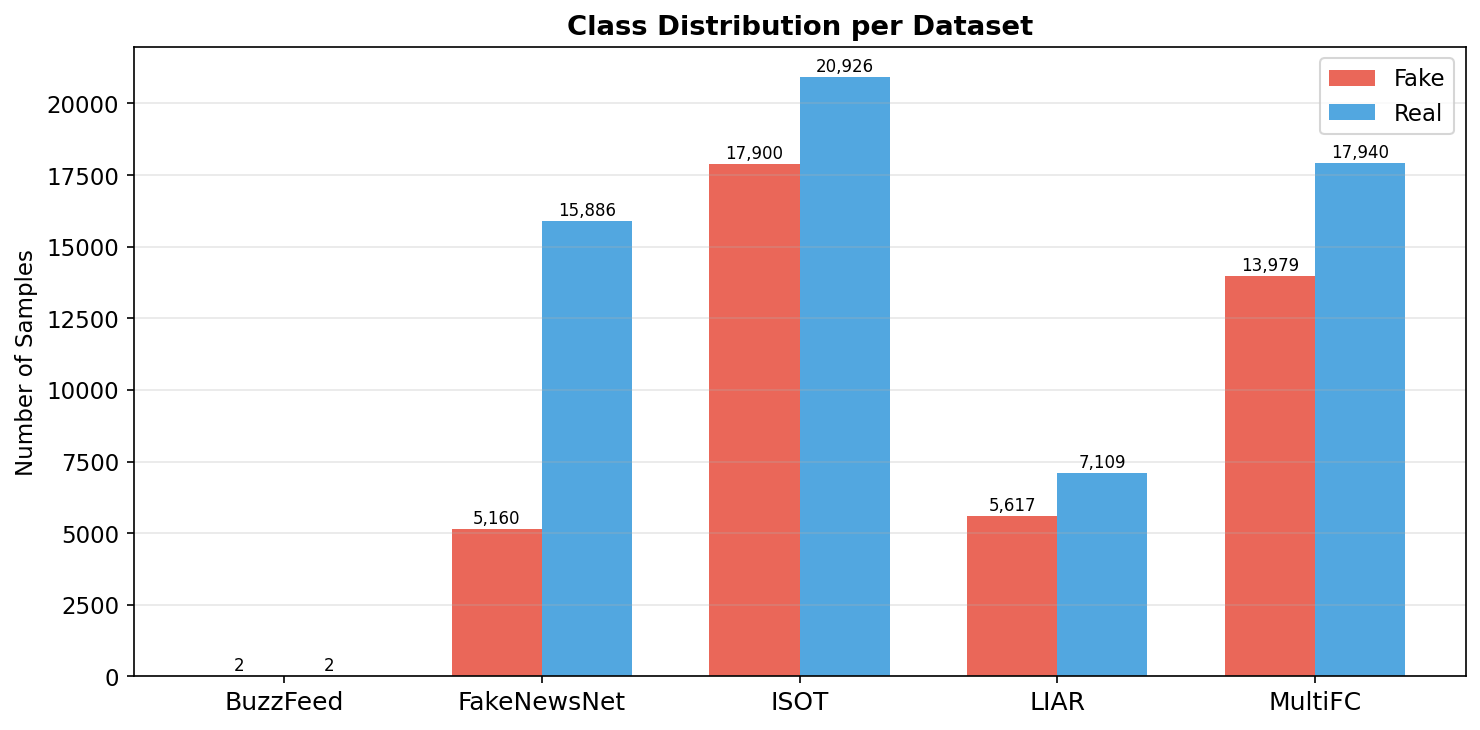

In [3]:
src = df.groupby(['source', 'label']).size().unstack(fill_value=0)
src.columns = ['Fake', 'Real']
src['Total'] = src.sum(axis=1)
print(src.to_string())

fig, ax = plt.subplots(figsize=(10, 5))
width = 0.35
x = np.arange(len(src))
ax.bar(x - width/2, src['Fake'], width, label='Fake', color='#e74c3c', alpha=0.85)
ax.bar(x + width/2, src['Real'], width, label='Real', color='#3498db', alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(src.index, fontsize=12)
ax.set_ylabel('Number of Samples')
ax.set_title('Class Distribution per Dataset')
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)
for i, (f, r) in enumerate(zip(src['Fake'], src['Real'])):
    ax.text(i - width/2, f + 50, f'{f:,}', ha='center', va='bottom', fontsize=8)
    ax.text(i + width/2, r + 50, f'{r:,}', ha='center', va='bottom', fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'dataset_distribution.png'), dpi=150, bbox_inches='tight')
plt.show()

## 3. Text Length Analysis

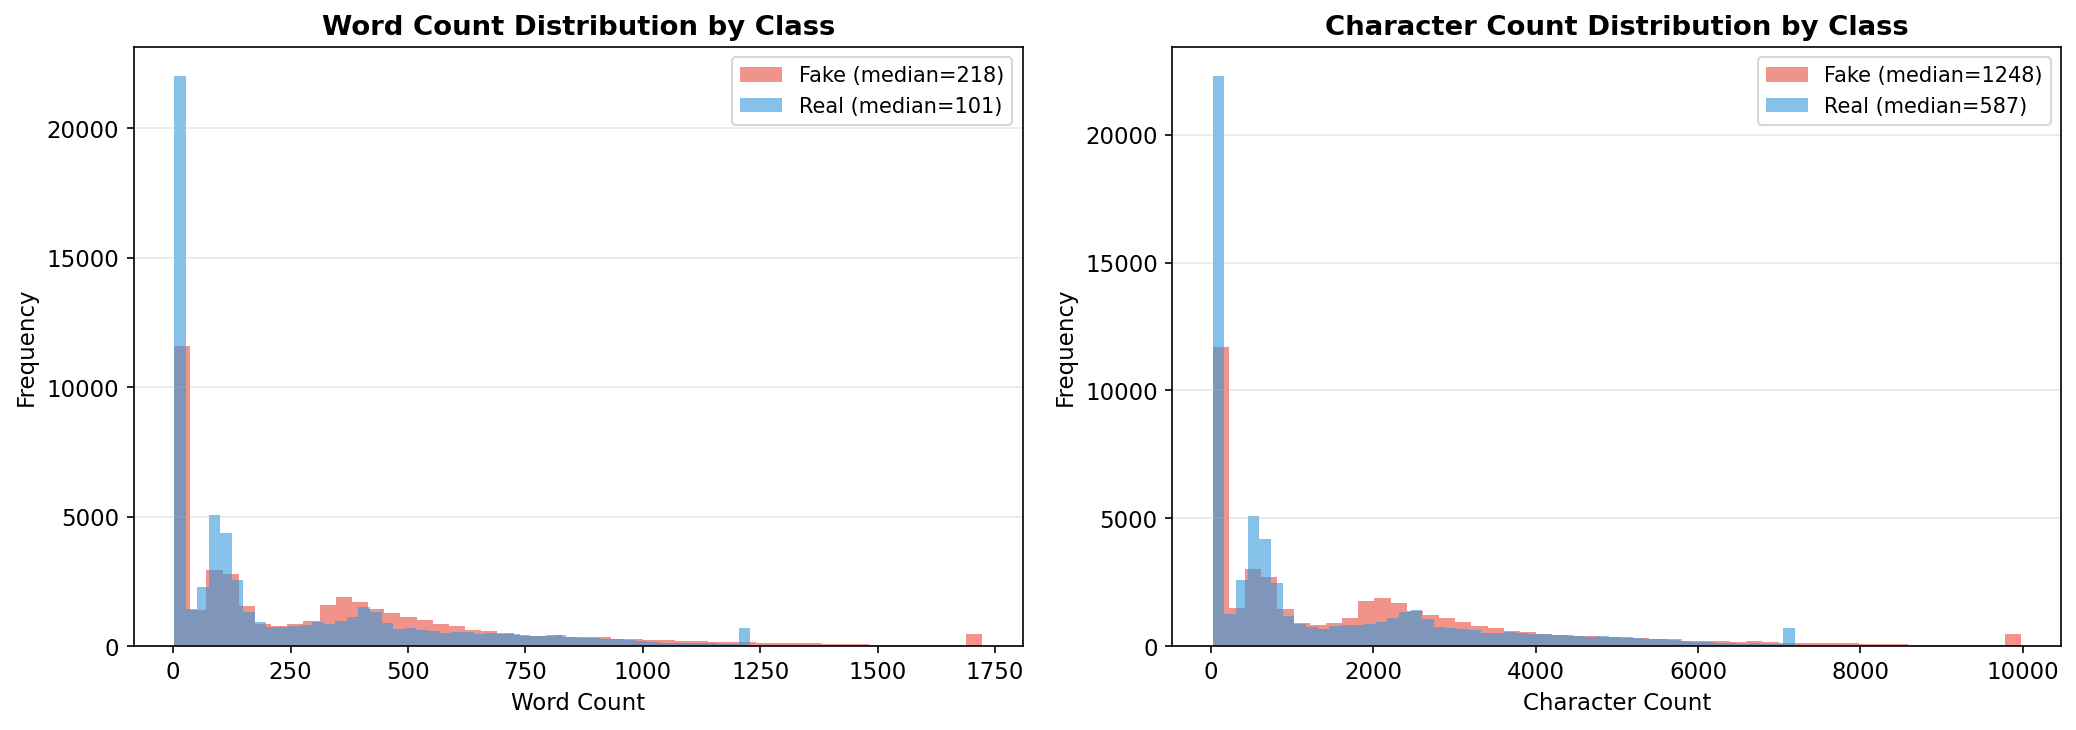


Word count stats by class:
         count   mean    std  min   25%    50%    75%     max
label                                                        
0      42658.0  342.9  417.6  2.0  26.0  218.0  495.0  8295.0
1      61863.0  234.5  305.1  2.0  15.0  101.0  383.0  5254.0


In [4]:
df['text_len']  = df['text_clean'].str.split().str.len()
df['char_len']  = df['text_clean'].str.len()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col, label in zip(axes, ['text_len', 'char_len'], ['Word Count', 'Character Count']):
    for lbl, color, name in [(0, '#e74c3c', 'Fake'), (1, '#3498db', 'Real')]:
        data = df[df.label == lbl][col]
        ax.hist(data.clip(upper=data.quantile(0.99)), bins=50,
                alpha=0.6, color=color, label=f'{name} (median={data.median():.0f})')
    ax.set_xlabel(label)
    ax.set_ylabel('Frequency')
    ax.set_title(f'{label} Distribution by Class')
    ax.legend(fontsize=10)
    ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'text_length_distribution.png'), dpi=150, bbox_inches='tight')
plt.show()

print('\nWord count stats by class:')
print(df.groupby('label')['text_len'].describe().round(1).to_string())

## 4. Overall Class Balance (Pie)

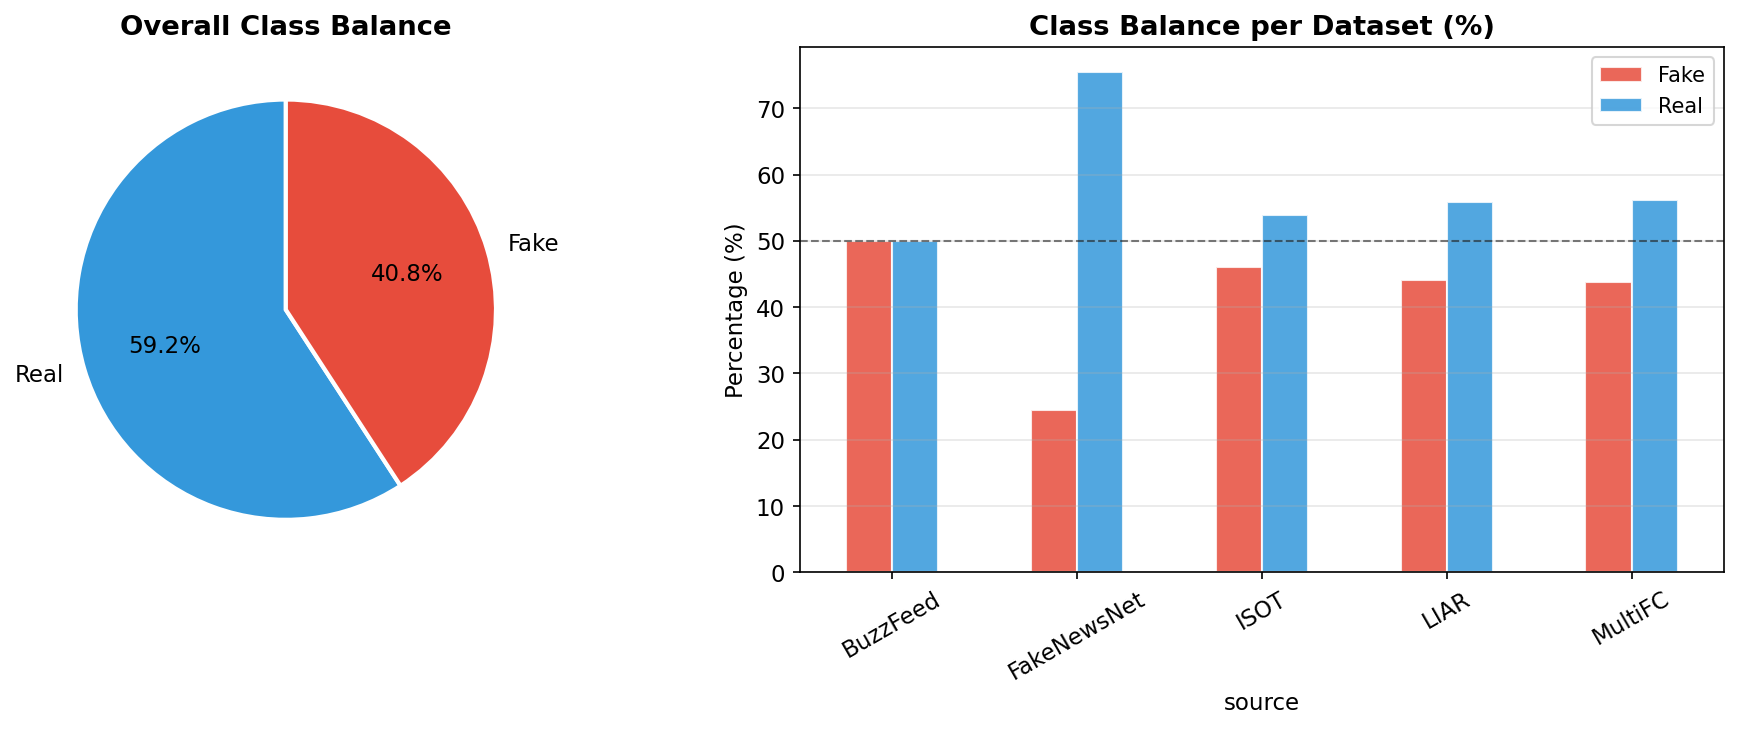

In [5]:
counts = df['label'].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Pie
axes[0].pie(counts.values, labels=['Real', 'Fake'], autopct='%1.1f%%',
            colors=['#3498db', '#e74c3c'], startangle=90,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[0].set_title('Overall Class Balance')

# Bar per source (stacked)
src_pct = src[['Fake','Real']].div(src['Total'], axis=0) * 100
src_pct.plot(kind='bar', ax=axes[1], color=['#e74c3c', '#3498db'],
             alpha=0.85, edgecolor='white')
axes[1].set_ylabel('Percentage (%)')
axes[1].set_title('Class Balance per Dataset (%)')
axes[1].tick_params(axis='x', rotation=30)
axes[1].legend(fontsize=10)
axes[1].grid(axis='y', alpha=0.3)
axes[1].axhline(50, color='black', linestyle='--', lw=1, alpha=0.5)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'class_balance.png'), dpi=150, bbox_inches='tight')
plt.show()

## 5. Top Word Frequencies (post-cleaning)

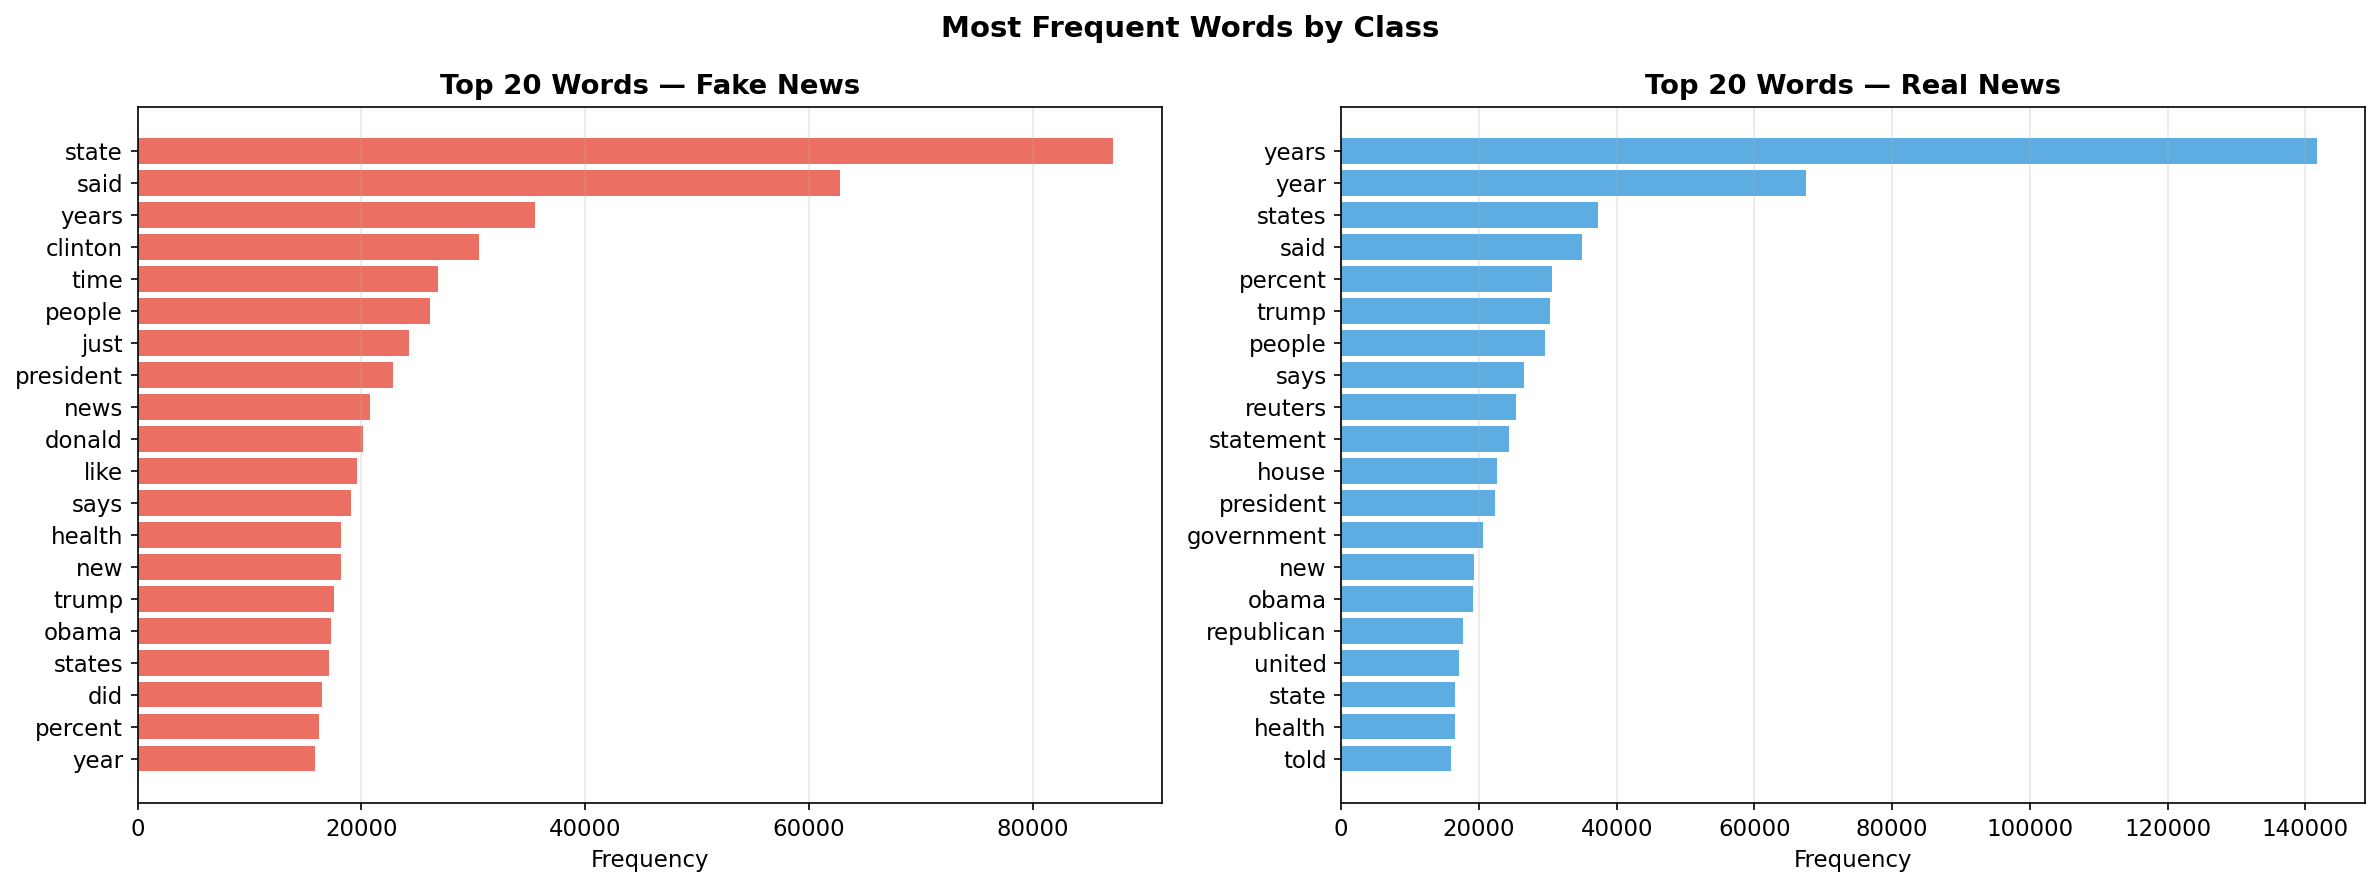

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer

# Top 20 unigrams by class
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, lbl, color, name in zip(axes, [0, 1], ['#e74c3c', '#3498db'], ['Fake', 'Real']):
    cv = CountVectorizer(max_features=20, stop_words='english')
    texts = df[df.label == lbl]['text_clean'].fillna('')
    cv.fit_transform(texts)
    freqs = sorted(zip(cv.vocabulary_.keys(),
                       cv.transform(texts).toarray().sum(axis=0)),
                   key=lambda x: x[1], reverse=True)[:20]
    words, counts_ = zip(*freqs)
    ax.barh(list(reversed(words)), list(reversed(counts_)), color=color, alpha=0.8)
    ax.set_xlabel('Frequency')
    ax.set_title(f'Top 20 Words — {name} News')
    ax.grid(axis='x', alpha=0.3)
plt.suptitle('Most Frequent Words by Class', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'top_words_by_class.png'), dpi=150, bbox_inches='tight')
plt.show()

## 6. TF-IDF Feature Exploration

TF-IDF vocabulary size : 50,000
Feature matrix shape   : (104521, 50000)
Sparsity               : 97.33%


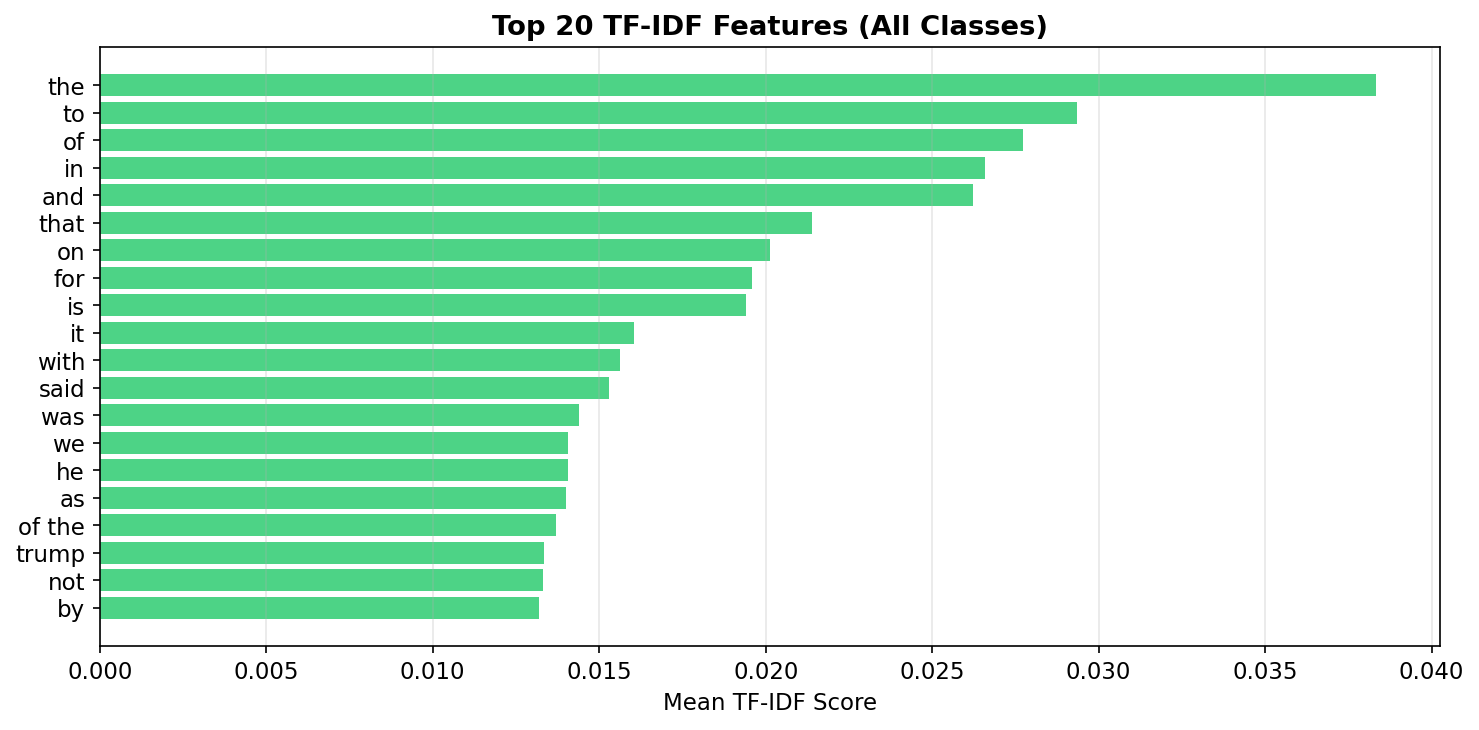

In [7]:
tfidf = TfidfVectorizer(max_features=50000, ngram_range=(1, 2),
                        sublinear_tf=True, min_df=2, max_df=0.95)
X_all_tfidf = tfidf.fit_transform(df['text_clean'].fillna(''))
print(f'TF-IDF vocabulary size : {len(tfidf.vocabulary_):,}')
print(f'Feature matrix shape   : {X_all_tfidf.shape}')
print(f'Sparsity               : {(1 - X_all_tfidf.nnz / np.prod(X_all_tfidf.shape)) * 100:.2f}%')

# Top TF-IDF terms overall
feat_names = np.array(tfidf.get_feature_names_out())
mean_tfidf  = np.asarray(X_all_tfidf.mean(axis=0)).flatten()
top_idx = mean_tfidf.argsort()[-20:][::-1]
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(feat_names[top_idx][::-1], mean_tfidf[top_idx][::-1], color='#2ecc71', alpha=0.85)
ax.set_xlabel('Mean TF-IDF Score')
ax.set_title('Top 20 TF-IDF Features (All Classes)')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'top_tfidf_features.png'), dpi=150, bbox_inches='tight')
plt.show()

## 7. Train / Test Split Summary

Split  Samples  Fake  Real  % Fake  % Real
Train    83616 34126 49490    40.8    59.2
 Test    20905  8532 12373    40.8    59.2


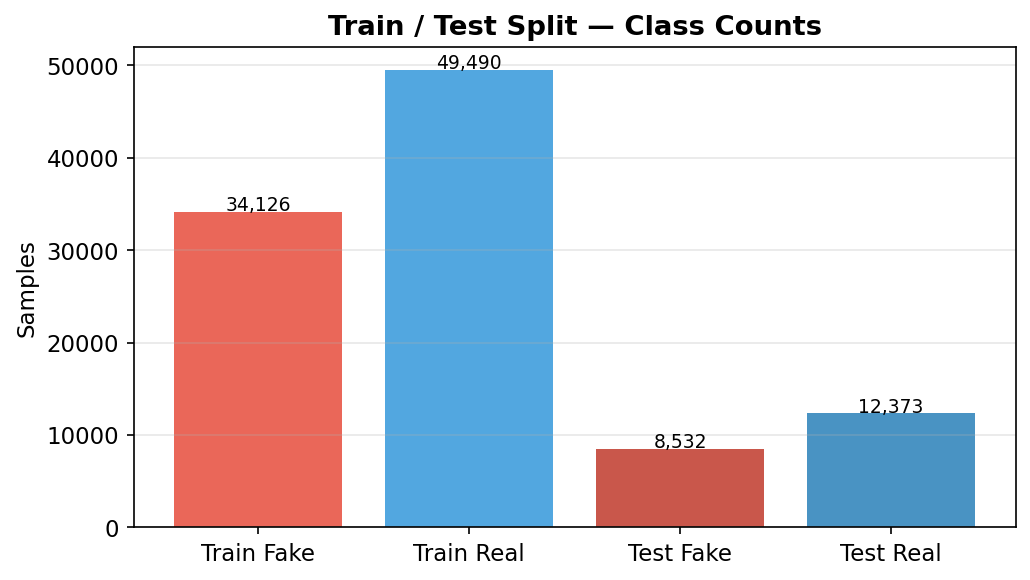


EDA complete — proceed to individual model notebooks.


In [8]:
summary = pd.DataFrame({
    'Split':   ['Train', 'Test'],
    'Samples': [len(X_train), len(X_test)],
    'Fake':    [(y_train==0).sum(), (y_test==0).sum()],
    'Real':    [(y_train==1).sum(), (y_test==1).sum()],
})
summary['% Fake'] = (summary['Fake'] / summary['Samples'] * 100).round(1)
summary['% Real'] = (summary['Real'] / summary['Samples'] * 100).round(1)
print(summary.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(['Train Fake','Train Real','Test Fake','Test Real'],
       [summary.loc[0,'Fake'], summary.loc[0,'Real'],
        summary.loc[1,'Fake'], summary.loc[1,'Real']],
       color=['#e74c3c','#3498db','#c0392b','#2980b9'], alpha=0.85)
ax.set_ylabel('Samples')
ax.set_title('Train / Test Split — Class Counts')
for i, v in enumerate([summary.loc[0,'Fake'], summary.loc[0,'Real'],
                        summary.loc[1,'Fake'], summary.loc[1,'Real']]):
    ax.text(i, v + 100, f'{v:,}', ha='center', fontsize=9)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'train_test_split.png'), dpi=150, bbox_inches='tight')
plt.show()
print('\nEDA complete — proceed to individual model notebooks.')